# Volumes and trading costs of ten CAC 40 stocks

An execution desk works client orders over the day. Before trading it needs two numbers: how much the stock will trade in the next session, which sets the pace of the order, and what the order will cost. This note answers both for ten large French stocks, with forecasts and pre-trade estimates produced by [`pipeline/volume_models.py`](../pipeline/volume_models.py) and [`pipeline/costs.py`](../pipeline/costs.py) (gold tables `fact_volume_forecast`, `fact_volume_evaluation`, `fact_liquidity` and `fact_cost`).

**Universe.** The ten largest CAC 40 weights on 31 March 2017, fixed before the 2018–2026 test period so that the selection does not favour the stocks that did well afterwards: TotalEnergies, Sanofi, BNP Paribas, LVMH, AXA, L'Oréal, Air Liquide, Airbus, Vinci and Danone.

**Data.** Daily open, high, low, close and volume from Yahoo Finance since 2008. Yahoo's volume equals the volume Euronext Paris publishes for these stocks (checked session by session over September–October 2026), so it covers Euronext's order book only, not the other venues where the same shares trade. Raw volumes are not redistributed: the gold tables express every volume as a multiple of the 20-day average daily volume (ADV) at the previous close.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").exists())
sys.path.insert(0, str(ROOT))
from pipeline import costs, evaluation
from pipeline.volume_models import calendar_flags

GOLD = ROOT / "data" / "gold"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
MODEL_COLORS = {"adv20": "#a9a8a3", "har_volume": "#1baf7a", "xgboost_volume": "#2a78d6"}
MODEL_NAMES = {
    "adv20": "20-day ADV",
    "har_volume": "HAR (log volume)",
    "xgboost_volume": "XGBoost (log volume)",
}
plt.rcParams.update(
    {
        "figure.figsize": (9, 3.6),
        "figure.dpi": 110,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": INK2,
        "ytick.color": INK2,
        "lines.linewidth": 1.5,
        "legend.frameon": False,
        "font.size": 9,
    }
)

names = pd.read_parquet(GOLD / "dim_instrument.parquet").set_index("instrument_id")["short_name"]
forecasts = pd.read_parquet(GOLD / "fact_volume_forecast.parquet").assign(
    date=lambda d: pd.to_datetime(d["date"])
)
scores = pd.read_parquet(GOLD / "fact_volume_evaluation.parquet")
liquidity = pd.read_parquet(GOLD / "fact_liquidity.parquet").assign(date=lambda d: pd.to_datetime(d["date"]))
cost = pd.read_parquet(GOLD / "fact_cost.parquet").assign(date=lambda d: pd.to_datetime(d["date"]))
traded = forecasts.dropna(subset=["actual_vs_adv"])
whole = scores.loc[scores["period"].str.contains("-"), "period"].iloc[0]
print(
    f"{forecasts['instrument_id'].nunique()} stocks; volume forecasts for {traded['date'].min():%d %b %Y} to "
    f"{traded['date'].max():%d %b %Y} ({traded['date'].nunique()} sessions), next session {forecasts['date'].max():%d %b %Y}; "
    f"costs from {cost['date'].min():%d %b %Y}"
)

10 stocks; volume forecasts for 03 Jan 2018 to 21 Oct 2026 (2253 sessions), next session 22 Oct 2026; costs from 03 Apr 2008


## 1. When volume is high and low

The baseline forecast of the next session's volume is the 20-day ADV. The ratio of actual volume to that ADV shows the regular patterns a forecast can use; all of them are known in advance from the calendar.

In [2]:
baseline = traded[traded["model_id"] == "adv20"].copy()
baseline = baseline.join(calendar_flags(pd.DatetimeIndex(baseline["date"].unique()).sort_values()), on="date")
baseline["log_ratio"] = np.log(baseline["actual_vs_adv"])
groups = {
    **{
        day: baseline["weekday"] == number
        for number, day in enumerate(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"])
    },
    "Third Friday (monthly expiry)": baseline["third_friday"] == 1,
    "Quarterly expiry (March, June, September, December)": baseline["quarterly_expiry"] == 1,
    "Last session of the month": baseline["month_end"] == 1,
    "Session before a holiday": baseline["pre_holiday"] == 1,
}
effects = pd.DataFrame(
    {
        "sessions": {
            label: int(mask.sum() / baseline["instrument_id"].nunique()) for label, mask in groups.items()
        },
        "volume / ADV (geometric mean)": {
            label: np.exp(baseline.loc[mask, "log_ratio"].mean()) for label, mask in groups.items()
        },
    }
).round(2)
print(
    f"All sessions: volume / ADV = {np.exp(baseline['log_ratio'].mean()):.3f} (geometric mean), {len(baseline)} stock-sessions"
)
effects

All sessions: volume / ADV = 0.943 (geometric mean), 22527 stock-sessions


,sessions,volume / ADV (geometric mean)
Monday,445,0.84
Tuesday,455,0.92
Wednesday,453,0.95
Thursday,453,0.96
Friday,444,1.06
Third Friday (monthly expiry),103,1.44
"Quarterly expiry (March, June, September, December)",35,2.35
Last session of the month,105,1.17
Session before a holiday,29,0.54


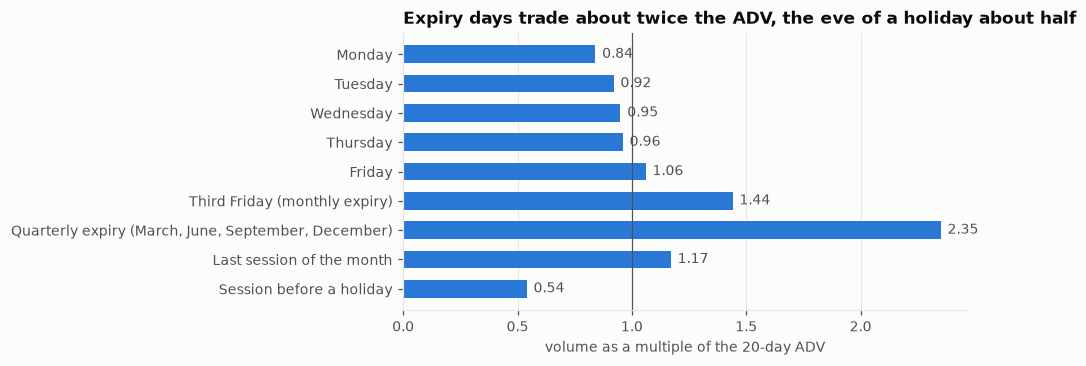

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.4))
labels = list(effects.index)[::-1]
values = effects["volume / ADV (geometric mean)"].loc[labels]
ax.set_axisbelow(True)
ax.barh(labels, values, color="#2a78d6", height=0.6)
ax.axvline(1.0, color=INK2, linewidth=0.8)
for y, value in enumerate(values):
    ax.text(value + 0.03, y, f"{value:.2f}", va="center", color=INK2)
ax.set_xlabel("volume as a multiple of the 20-day ADV")
ax.set_title("Expiry days trade about twice the ADV, the eve of a holiday about half")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Across all stocks and sessions, volume averages 0.943 times the ADV in geometric terms: the ADV, an arithmetic mean pulled up by a few very large sessions, overstates the typical session by 5.7%. Around that level the calendar moves volume a lot. Quarterly expiry days trade 2.35 times the ADV and other third Fridays push the monthly-expiry average to 1.44; the last session of the month trades 1.17 times, Friday 1.06 and Monday 0.84; the session before a holiday trades about half the ADV (0.54). A schedule built on the ADV alone trades too fast on quiet days and too slowly on expiry days.

## 2. Forecasting the next session's volume

The target is the log of the next session's volume, from inputs known before that session opens. Three forecasts are compared from 2018, all refitted at the start of each month on all past data (the last training row is dropped, since its target falls in the new month):

- **20-day ADV**, the reference desks use.
- **HAR on log volume** (in the spirit of Corsi, 2009): the last session's log volume and its 5- and 22-session means.
- **XGBoost** (Chen and Guestrin, 2016) on the HAR terms, the calendar flags of the session being forecast, the stock's EWMA volatility and the VIX, with fixed, shallow settings never tuned on the test period.

Losses: the mean squared error of the log volume (MSE), and the mean absolute percentage error of the volume (MAPE) for a business reading. Diebold-Mariano tests (Diebold and Mariano, 1995) compare squared log errors with the ADV's, with Newey-West variance.

In [4]:
def dm_against(model: str, reference: str, part: pd.DataFrame) -> float:
    wide = part.pivot(index="date", columns="model_id", values="forecast_vs_adv").dropna()
    actual = part.drop_duplicates("date").set_index("date")["actual_vs_adv"].reindex(wide.index)
    losses = {m: evaluation.squared_error(np.log(actual), np.log(wide[m])) for m in (model, reference)}
    return evaluation.diebold_mariano(losses[model], losses[reference], horizon=1)[1]


period_scores = scores[scores["period"] == whole]
table = period_scores.pivot(index="instrument_id", columns="model_id", values=["mse_log", "mape"])
table.columns = [f"{metric} {MODEL_NAMES[model]}" for metric, model in table.columns]
table["DM p, HAR vs ADV"] = period_scores[period_scores["model_id"] == "har_volume"].set_index(
    "instrument_id"
)["dm_p_vs_adv"]
table["DM p, XGBoost vs ADV"] = period_scores[period_scores["model_id"] == "xgboost_volume"].set_index(
    "instrument_id"
)["dm_p_vs_adv"]
table["DM p, XGBoost vs HAR"] = {
    instrument: dm_against("xgboost_volume", "har_volume", part)
    for instrument, part in traded.groupby("instrument_id")
}
table = table.rename(index=names).sort_index()
print(
    f"{whole}, {int(period_scores['n_days'].min())}-{int(period_scores['n_days'].max())} sessions per stock"
)
table.round(4)

2018-2026, 2250-2253 sessions per stock


,mse_log 20-day ADV,mse_log HAR (log volume),mse_log XGBoost (log volume),mape 20-day ADV,mape HAR (log volume),mape XGBoost (log volume),"DM p, HAR vs ADV","DM p, XGBoost vs ADV","DM p, XGBoost vs HAR"
instrument_id,,,,,,,,,
AXA,0.1558,0.1228,0.1068,0.3346,0.2796,0.2753,0.0,0.0,0.0001
Air Liquide,0.1305,0.1098,0.0909,0.3007,0.2641,0.2500,0.0,0.0,0.0000
Airbus,0.1546,0.1178,0.1052,0.3364,0.2803,0.2668,0.0,0.0,0.0004
BNP Paribas,0.1549,0.1171,0.0978,0.3339,0.2780,0.2588,0.0,0.0,0.0000
Danone,0.1374,0.1102,0.0915,0.3094,0.2644,0.2518,0.0,0.0,0.0000
L'Oréal,0.1387,0.1129,0.0879,0.3122,0.2662,0.2414,0.0,0.0,0.0000
LVMH,0.1499,0.1205,0.1014,0.3246,0.2750,0.2545,0.0,0.0,0.0000
Sanofi,0.1425,0.1135,0.0904,0.3118,0.2610,0.2419,0.0,0.0,0.0000
TotalEnergies,0.1358,0.1091,0.0826,0.3044,0.2512,0.2244,0.0,0.0,0.0000


In [5]:
summary = period_scores.groupby("model_id")[["mse_log", "mape"]].mean().rename(index=MODEL_NAMES)
summary["stocks better than ADV, p < 0.05"] = (
    period_scores.groupby("model_id")
    .apply(
        lambda part: int(((part["dm_stat_vs_adv"] < 0) & (part["dm_p_vs_adv"] < 0.05)).sum()),
        include_groups=False,
    )
    .rename(index=MODEL_NAMES)
)
stress = scores[scores["period"].isin(["2020", "2022"])]
by_year = stress.pivot_table(index="model_id", columns="period", values="mse_log", aggfunc="mean").rename(
    index=MODEL_NAMES
)
by_year.columns = [f"MSE {year}" for year in by_year.columns]
significant = (
    stress[stress["model_id"] != "adv20"].groupby(["model_id", "period"])["dm_p_vs_adv"].max().unstack()
)
significant = significant.rename(index=MODEL_NAMES)
significant.columns = [f"largest DM p vs ADV, {year}" for year in significant.columns]
bias = baseline["log_ratio"].mean()
print(
    f"ADV bias: mean log(actual / ADV) = {bias:.3f}, so the ADV overstates the typical session by {1 - np.exp(bias):.1%}"
)
summary.join(by_year).join(significant).round(4)

ADV bias: mean log(actual / ADV) = -0.058, so the ADV overstates the typical session by 5.7%


,mse_log,mape,"stocks better than ADV, p < 0.05",MSE 2020,MSE 2022,"largest DM p vs ADV, 2020","largest DM p vs ADV, 2022"
model_id,,,,,,,
20-day ADV,0.1445,0.3181,0,0.1797,0.1231,NaN,NaN
HAR (log volume),0.1152,0.2690,10,0.1176,0.0914,0.0007,0.0096
XGBoost (log volume),0.0947,0.2512,10,0.1020,0.0784,0.0018,0.0111


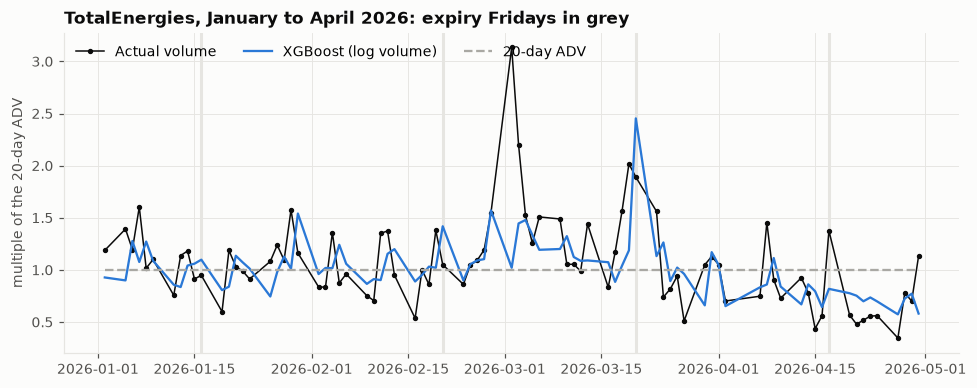

In [6]:
stock, window = "TTE", slice("2026-01-01", "2026-04-30")
one = (
    forecasts[(forecasts["instrument_id"] == stock)]
    .pivot(index="date", columns="model_id", values="forecast_vs_adv")
    .loc[window]
)
actual = (
    forecasts[(forecasts["instrument_id"] == stock) & (forecasts["model_id"] == "adv20")]
    .set_index("date")["actual_vs_adv"]
    .loc[window]
)
fig, ax = plt.subplots()
ax.plot(actual.index, actual, color=INK, linewidth=1.0, marker="o", markersize=2.5, label="Actual volume")
ax.plot(
    one.index,
    one["xgboost_volume"],
    color=MODEL_COLORS["xgboost_volume"],
    label=MODEL_NAMES["xgboost_volume"],
)
ax.plot(one.index, one["adv20"], color=MODEL_COLORS["adv20"], linestyle="--", label=MODEL_NAMES["adv20"])
expiries = calendar_flags(one.index)
for day in expiries.index[expiries["third_friday"] == 1]:
    ax.axvline(day, color=GRID, linewidth=2, zorder=0)
ax.set_ylabel("multiple of the 20-day ADV")
ax.set_title(f"{names[stock]}, January to April 2026: expiry Fridays in grey")
ax.legend(loc="upper left", ncol=3)
plt.tight_layout()
plt.show()

Over 2018–2026 (about 2,250 sessions per stock), both models beat the ADV on every stock with Diebold-Mariano p-values below 0.0001. On average across stocks, the squared log error falls from 0.145 (ADV) to 0.115 (HAR) and 0.095 (XGBoost), a third less than the desks' reference, and the absolute percentage error from 31.8% to 26.9% and 25.1%. XGBoost also beats HAR on all ten stocks (p ≤ 0.0004). For volatility in [`02_volatility`](02_volatility.ipynb) it beat HAR only on the three equity indices and did worse on gold and the bond; volume has strong calendar effects that a linear model on past volume cannot see. The ranking holds in the stress years: in 2020 the ADV's error rises to 0.180 against 0.102 for XGBoost, and both models stay significantly better than the ADV on every stock in 2020 and in 2022 (largest p-values 0.002 and 0.011). This agrees with Goyenko et al. (2024), who find stock volume highly predictable, especially with machine learning.

Part of the gain is the ADV's bias: forecasting the log of volume targets the typical session, while the ADV is an arithmetic mean. On TotalEnergies in early 2026 the model raises its forecast before the expiry Fridays (grey lines), most clearly on the March quarterly expiry, but it misses one-off spikes such as early March, which no calendar flag anticipates.

## 3. The bid-ask spread from daily prices

Quote data is not free, so the spread is estimated from daily highs and lows (Corwin and Schultz, 2012): a day's range reflects both volatility and the spread, and over two days the volatility part doubles while the spread does not. The paper sets negative two-day estimates to zero before averaging. With spreads of a few ticks, as for these stocks, the daily estimates are dominated by noise, and clipping them keeps only the positive half of that noise. The pipeline therefore averages the signed estimates over 63 sessions and floors the mean at zero.

In [7]:
spread = liquidity.set_index("date").groupby("instrument_id")
textbook = spread["spread_estimate_bp"].transform(lambda s: s.clip(lower=0).rolling(22).mean())
liquidity_view = liquidity.assign(textbook_bp=textbook.to_numpy())
since = liquidity_view[liquidity_view["date"] >= "2018-01-01"]
spreads = (
    pd.DataFrame(
        {
            "negative daily estimates": since.groupby("instrument_id")["spread_estimate_bp"].apply(
                lambda s: (s < 0).mean()
            ),
            "daily estimate std (bp)": since.groupby("instrument_id")["spread_estimate_bp"].std(),
            "textbook median (bp)": since.groupby("instrument_id")["textbook_bp"].median(),
            "pipeline median (bp)": since.groupby("instrument_id")["spread_bp"].median(),
            "pipeline at zero": since.groupby("instrument_id")["spread_bp"].apply(lambda s: (s == 0).mean()),
        }
    )
    .rename(index=names)
    .sort_index()
)
print(
    f"From {since['date'].min():%d %b %Y}; textbook = negatives set to zero, 22-session mean; pipeline = 63-session mean, floored at zero"
)
spreads.round(2)

From 02 Jan 2018; textbook = negatives set to zero, 22-session mean; pipeline = 63-session mean, floored at zero


,negative daily estimates,daily estimate std (bp),textbook median (bp),pipeline median (bp),pipeline at zero
instrument_id,,,,,
AXA,0.41,122.24,40.25,5.14,0.35
Air Liquide,0.39,101.20,38.04,7.20,0.27
Airbus,0.42,180.72,51.57,0.00,0.58
BNP Paribas,0.43,154.68,51.88,1.83,0.46
Danone,0.40,102.14,37.42,2.87,0.40
L'Oréal,0.39,119.61,45.81,7.03,0.28
LVMH,0.42,139.77,50.00,2.66,0.43
Sanofi,0.40,119.15,43.60,4.01,0.38
TotalEnergies,0.41,144.66,45.76,1.14,0.46


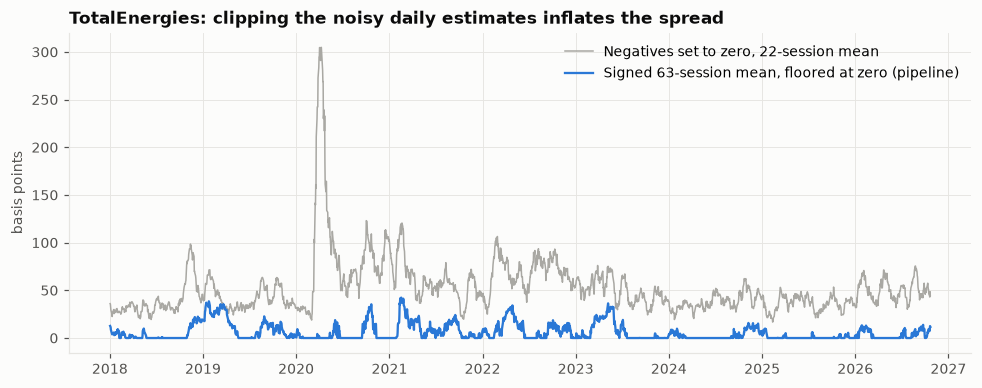

In [8]:
view = liquidity_view[
    (liquidity_view["instrument_id"] == "TTE") & (liquidity_view["date"] >= "2018-01-01")
].set_index("date")
fig, ax = plt.subplots()
ax.plot(
    view.index,
    view["textbook_bp"],
    color="#a9a8a3",
    linewidth=1.0,
    label="Negatives set to zero, 22-session mean",
)
ax.plot(
    view.index, view["spread_bp"], color="#2a78d6", label="Signed 63-session mean, floored at zero (pipeline)"
)
ax.set_ylabel("basis points")
ax.set_title("TotalEnergies: clipping the noisy daily estimates inflates the spread")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

Since 2018, 39% to 43% of the daily estimates are negative and their standard deviation is 101 to 181 bp, an order of magnitude above the spreads of stocks this liquid. Clipping them before averaging gives medians of 37 to 52 bp, which mainly measures that noise; the signed 63-session mean gives 0 to 7 bp, but it is floored at zero on 27% to 58% of sessions and barely responds in March 2020, when spreads widened. Daily-price estimators were designed and validated on broad cross-sections that include less liquid stocks; for the largest CAC 40 names they cannot resolve spreads of a few ticks. Newer estimators that also use the open and close (Ardia, Guidotti and Kroencke, 2024) face the same limit: the noise comes from the daily data, not the formula. The spread term is kept in the cost model as a small, uncertain component; a desk would replace it with quoted spreads.

## 4. The cost of an order

The pre-trade cost of an order executed over the next session is half the spread plus the market impact, which follows the square-root law found across markets and periods (Tóth et al., 2011; Sato and Kanazawa, 2024):

cost = spread / 2 + Y × σ × √(Q / V)

with σ the stock's daily volatility (EWMA forecast at the previous close), Q / V the order's share of the session's volume (its participation) and Y = 1, the upper end of the 0.5–1 range reported for stocks and futures (Tóth, Eisler and Bouchaud, 2016), so the estimate errs on the costly side. An order four times larger costs twice as much per share in impact.

In [9]:
latest_day = cost["date"].max()
latest = cost[cost["date"] == latest_day].pivot(
    index="instrument_id", columns="participation", values="cost_bp"
)
latest.columns = [f"{participation:.0%} of volume" for participation in latest.columns]
inputs = liquidity[liquidity["date"] == latest_day].set_index("instrument_id")[["spread_bp", "volatility_bp"]]
print(f"Pre-trade cost in basis points for the session of {latest_day:%d %b %Y}")
inputs.join(latest).rename(index=names).sort_values("10% of volume").round(1)

Pre-trade cost in basis points for the session of 22 Oct 2026


,spread_bp,volatility_bp,1% of volume,5% of volume,10% of volume,20% of volume
instrument_id,,,,,,
Air Liquide,7.4,97.9,13.5,25.6,34.7,47.5
AXA,8.6,109.9,15.3,28.9,39.1,53.5
L'Oréal,1.9,126.0,13.6,29.1,40.8,57.3
Vinci,15.9,112.1,19.2,33.0,43.4,58.1
TotalEnergies,11.6,119.9,17.8,32.6,43.7,59.5
Danone,13.9,133.2,20.3,36.7,49.1,66.5
BNP Paribas,0.0,157.2,15.7,35.2,49.7,70.3
LVMH,16.6,135.3,21.8,38.6,51.1,68.8
Sanofi,17.2,147.0,23.3,41.5,55.1,74.4


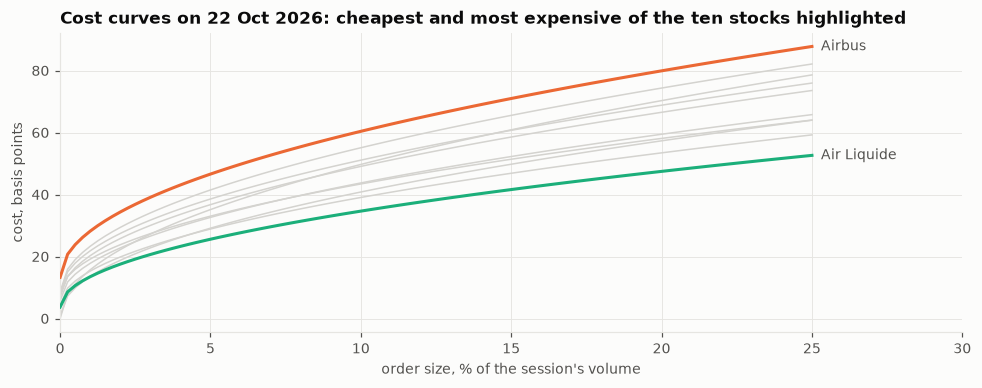

In [10]:
participation = np.linspace(0.0, 0.25, 101)
today = liquidity[liquidity["date"] == latest_day].set_index("instrument_id")
order = today.assign(
    at_10=today["spread_bp"] / 2 + costs.impact_bp(today["volatility_bp"], 0.10)
).sort_values("at_10")
highlight = {order.index[0]: "#1baf7a", order.index[-1]: "#eb6834"}
fig, ax = plt.subplots()
for instrument, row in today.iterrows():
    curve = row["spread_bp"] / 2 + costs.impact_bp(row["volatility_bp"], participation)
    color = highlight.get(instrument, "#d4d3cf")
    ax.plot(
        participation * 100,
        curve,
        color=color,
        linewidth=2 if instrument in highlight else 1,
        zorder=3 if instrument in highlight else 2,
    )
    if instrument in highlight:
        ax.text(25.3, curve[-1], names[instrument], va="center", color=INK2)
ax.set_xlim(0, 30)
ax.set_xlabel("order size, % of the session's volume")
ax.set_ylabel("cost, basis points")
ax.set_title(
    f"Cost curves on {latest_day:%d %b %Y}: cheapest and most expensive of the ten stocks highlighted"
)
plt.tight_layout()
plt.show()

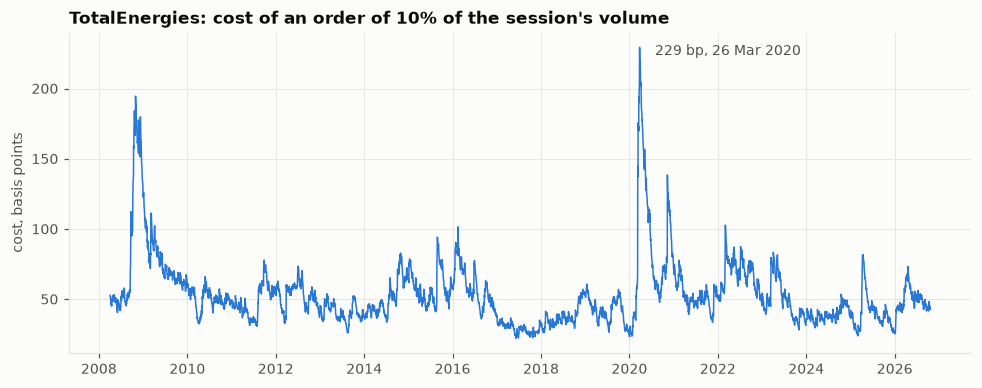

median 48.6 bp; 153.5 bp on average in March 2020; latest 43.7 bp


In [11]:
history = cost[(cost["instrument_id"] == "TTE") & (cost["participation"] == 0.10)].set_index("date")[
    "cost_bp"
]
fig, ax = plt.subplots()
ax.plot(history.index, history, color="#2a78d6", linewidth=1.0)
peak = history.idxmax()
ax.annotate(
    f"{history.max():.0f} bp, {peak:%d %b %Y}",
    (peak, history.max()),
    xytext=(10, -5),
    textcoords="offset points",
    color=INK2,
)
ax.set_ylabel("cost, basis points")
ax.set_title("TotalEnergies: cost of an order of 10% of the session's volume")
plt.tight_layout()
plt.show()
print(
    f"median {history.median():.1f} bp; {history.loc['2020-03'].mean():.1f} bp on average in March 2020; latest {history.iloc[-1]:.1f} bp"
)

For the session of 22 October 2026, an order of 10% of the session's volume costs from 34.7 bp (Air Liquide) to 60.4 bp (Airbus); 1% costs 13.5 to 28.2 bp and 20% costs 47.5 to 79.9 bp. Beyond a few percent of the volume the impact term dominates the half-spread, so the ranking of stocks follows their volatility, except where a noisy spread estimate lifts a stock (Airbus). Costs move with volatility: for TotalEnergies, the 10% order costs 48.6 bp in the median session since April 2008 but 153.5 bp on average in March 2020, with a peak of 229 bp on 26 March 2020. A fixed cost table calibrated in calm markets would understate stress-period costs about threefold.

In [12]:
check_stock, check_size = "TTE", 0.07
row = liquidity[(liquidity["date"] == latest_day) & (liquidity["instrument_id"] == check_stock)].iloc[0]
check = row["spread_bp"] / 2 + costs.impact_bp(row["volatility_bp"], check_size)
print(
    f"{names[check_stock]}, {check_size:.0%} of volume, session of {latest_day:%d %b %Y}: spread {row['spread_bp']:.2f} bp, volatility {row['volatility_bp']:.2f} bp, cost {check:.2f} bp"
)

TotalEnergies, 7% of volume, session of 22 Oct 2026: spread 11.63 bp, volatility 119.94 bp, cost 37.55 bp


The Execution page of the report computes the same formula in DAX for any order size chosen with a slider. For TotalEnergies at 7% of the volume on the session of 22 October 2026 it must return the 37.55 bp above.

## 5. Conclusions and consequences

| Finding | Consequence |
|---|---|
| XGBoost cuts the squared log error of the next session's volume by a third against the 20-day ADV and beats HAR on all ten stocks, also in 2020 and 2022 | Use the model's forecast to set the participation rate; keep the ADV as reference and fallback |
| Quarterly expiries trade 2.35 times the ADV, the eve of a holiday 0.54 times, Mondays 0.84 times | Calendar flags are the main gain over a linear model; earnings dates, not available here, are the next candidate |
| Spreads estimated from daily highs and lows are dominated by noise for these stocks | The spread term is small and uncertain; replace it with quoted spreads where available |
| An order of 10% of the volume costs 35 to 60 bp today and three times its median in March 2020 | Refresh pre-trade costs daily with volatility; size orders down when volatility jumps |

**Limits.** Volume is Euronext Paris only; part of the trading in these shares happens on other venues, so participation in total market volume is lower than computed here. The impact constant comes from published studies, not from the desk's own executions: post-trade TCA on real orders would calibrate it. The cost model is a one-session estimate; it ignores how the order is scheduled within the day and the price drift while it is worked.

## References

- Ardia, D., Guidotti, E., & Kroencke, T. A. (2024). Efficient estimation of bid–ask spreads from open, high, low, and close prices. *Journal of Financial Economics*, 161, 103916.
- Białkowski, J., Darolles, S., & Le Fol, G. (2008). Improving VWAP strategies: A dynamic volume approach. *Journal of Banking & Finance*, 32(9), 1709–1722.
- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD Conference*, 785–794.
- Corsi, F. (2009). A simple approximate long-memory model of realized volatility. *Journal of Financial Econometrics*, 7(2), 174–196.
- Corwin, S. A., & Schultz, P. (2012). A simple way to estimate bid-ask spreads from daily high and low prices. *Journal of Finance*, 67(2), 719–760.
- Diebold, F. X., & Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics*, 13(3), 253–263.
- Goyenko, R., Kelly, B. T., Moskowitz, T. J., Su, Y., & Zhang, C. (2024). Trading volume alpha. *NBER Working Paper* 33037.
- Sato, Y., & Kanazawa, K. (2024). Strict universality of the square-root law in price impact across stocks: A complete survey of the Tokyo Stock Exchange. arXiv:2411.13965.
- Tóth, B., Eisler, Z., & Bouchaud, J.-P. (2016). The square-root impact law also holds for option markets. arXiv:1602.03043.
- Tóth, B., Lempérière, Y., Deremble, C., de Lataillade, J., Kockelkoren, J., & Bouchaud, J.-P. (2011). Anomalous price impact and the critical nature of liquidity in financial markets. *Physical Review X*, 1(2), 021006.